[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/revantg/era-v5-session9-loss-harness/blob/main/loss_harness.ipynb)

Outputs are from the reported run on an NVIDIA RTX PRO 6000 Blackwell (bf16 autocast, 5,000 steps per training run). The notebook was authored in marimo ([`loss_harness.py`](loss_harness.py)) and runs top to bottom in plain Jupyter/Colab after the install cell.

In [ ]:
# Colab / Jupyter: the notebook uses marimo's mo.md / mo.vstack for display
%pip install -q marimo tokenizers huggingface_hub pyarrow

# Session 9 · A loss harness you can read, plus one extra head

A small GPT (10.7M parameters, TinyStories, a BPE vocabulary of 8,192) used as a test bench for the few lines between `model(tokens)` and the scalar loss.

* **Part 1** makes the starter harness correct and observable: every shape, the shift printed as strings, padding, packing, perplexity at init, tied vs untied heads, and the peak memory of ordinary vs chunked cross-entropy.
* **Part 2** adds a second head that predicts token `t+2` and follows both losses through training.

The scale-down keeps V5's ratio: `V / D = 8192 / 256 = 32`, the same as `131072 / 4096 = 32`, so the logits tensor is 32× the hidden state that produced it here too.

The write-up with the seven Part 1 numbers and the two Part 2 losses is the last cell.

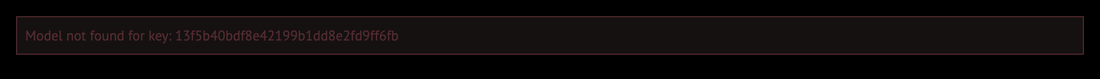

In [ ]:
import marimo as mo
import math, time, os, base64, warnings, logging
from dataclasses import dataclass, replace
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def svg(name):
    """Embed a figure from ./figures as a data URI, so the HTML export is self-contained."""
    _b = base64.b64encode((mo.notebook_dir() / "figures" / f"{name}.svg").read_bytes()).decode()
    return mo.Html(f'<img src="data:image/svg+xml;base64,{_b}" style="width:100%;max-width:1150px">')

In [ ]:
@dataclass(frozen=True)
class Cfg:
    V: int = 8192       # vocabulary size
    T: int = 256        # context length
    d: int = 256        # model width
    L: int = 8          # transformer blocks
    h: int = 8          # attention heads
    ff: int = 704       # SwiGLU hidden width (2/3 * 4d, rounded to 64)
    n_future: int = 1   # output heads: head k predicts token t+k
    tie: bool = False   # head 1 reuses tok_emb


CFG = Cfg()
B, STEPS, LR = 64, 5000, 2e-3
TOK_STORIES, TRAIN_STORIES, VAL_STORIES = 100_000, 400_000, 4_000
dev = "cuda" if torch.cuda.is_available() else "cpu"
AMP = dict(device_type=dev, dtype=torch.bfloat16, enabled=dev == "cuda")

_g = torch.cuda.get_device_properties(0) if dev == "cuda" else None
mo.md(f"""
**Hardware** · {_g.name if _g else "CPU"} · {(_g.total_memory / 2**30) if _g else 0:.0f} GiB · torch {torch.__version__} · {os.cpu_count()} CPUs

**Config** · `B={B}  T={CFG.T}  D={CFG.d}  layers={CFG.L}  heads={CFG.h}  V={CFG.V}` · {STEPS:,} optimizer steps per training run · bf16 autocast
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><strong>Hardware</strong> · NVIDIA RTX PRO 6000 Blackwell Server Edition · 95 GiB · torch 2.11.0+cu130 · 20 CPUs</span>
<span class="paragraph"><strong>Config</strong> · <code>B=64  T=256  D=256  layers=8  heads=8  V=8192</code> · 5,000 optimizer steps per training run · bf16 autocast</span></span>

## Data and tokenizer

TinyStories, one parquet shard. A byte-level BPE with two special tokens: `<pad>` = 0 and `<eos>` = 1. Every story ends in `<eos>`, then all the stories are concatenated into one stream, and training windows are cut from that stream at random. A window usually contains more than one story, which is the packing that Part 1 item 4 has to handle.

In [ ]:
def _read(fname, n):
    _path = hf_hub_download("roneneldan/TinyStories", fname, repo_type="dataset")
    return [t.strip() for t in pq.read_table(_path, columns=["text"]).slice(0, n).column("text").to_pylist()]


_t0 = time.time()
_train_text = _read("data/train-00000-of-00004-2d5a1467fff1081b.parquet", TRAIN_STORIES)
_val_text = _read("data/validation-00000-of-00001-869c898b519ad725.parquet", VAL_STORIES)

tok = Tokenizer(models.BPE())
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok.decoder = decoders.ByteLevel()
tok.train_from_iterator(_train_text[:TOK_STORIES], trainers.BpeTrainer(
    vocab_size=CFG.V, special_tokens=["<pad>", "<eos>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False))
PAD, EOS = tok.token_to_id("<pad>"), tok.token_to_id("<eos>")
assert tok.get_vocab_size() == CFG.V and (PAD, EOS) == (0, 1)

_train_docs = [e.ids + [EOS] for e in tok.encode_batch(_train_text)]
val_docs = [e.ids + [EOS] for e in tok.encode_batch(_val_text)]
story_lens = np.array([len(d) for d in _train_docs])


def _stream(docs):
    return torch.from_numpy(np.concatenate([np.asarray(d, dtype=np.int64) for d in docs])).to(dev)


train_ids, val_ids = _stream(_train_docs), _stream(val_docs)
mo.md(f"""
| | stories | tokens |
|---|---:|---:|
| train stream | {len(story_lens):,} | {len(train_ids):,} |
| validation stream | {len(val_docs):,} | {len(val_ids):,} |

Tokenizer `V={tok.get_vocab_size():,}`, `<pad>={PAD}`, `<eos>={EOS}`, trained on {TOK_STORIES:,} stories. Data and tokenizer took {time.time() - _t0:.0f}s.
Story length (tokens, including `<eos>`): median {int(np.median(story_lens))}, p90 {int(np.percentile(story_lens, 90))}. A {CFG.T}-token training run of {STEPS:,} × {B} windows reads {STEPS * B * CFG.T / len(train_ids):.2f} epochs of the stream.
""")

<span class="markdown prose dark:prose-invert contents"><table>
<thead>
<tr>
<th></th>
<th style="text-align: right;">stories</th>
<th style="text-align: right;">tokens</th>
</tr>
</thead>
<tbody>
<tr>
<td>train stream</td>
<td style="text-align: right;">400,000</td>
<td style="text-align: right;">88,530,314</td>
</tr>
<tr>
<td>validation stream</td>
<td style="text-align: right;">4,000</td>
<td style="text-align: right;">799,339</td>
</tr>
</tbody>
</table>
<span class="paragraph">Tokenizer <code>V=8,192</code>, <code>&lt;pad&gt;=0</code>, <code>&lt;eos&gt;=1</code>, trained on 100,000 stories. Data and tokenizer took 32s.
Story length (tokens, including <code>&lt;eos&gt;</code>): median 189, p90 359. A 256-token training run of 5,000 × 64 windows reads 0.93 epochs of the stream.</span></span>

In [ ]:
def tstr(i):
    """One token id as a readable string: ␣ marks a leading space, ↵ a newline."""
    i = int(i)
    return "<pad>" if i == PAD else "<eos>" if i == EOS else tok.decode([i]).replace(" ", "␣").replace("\n", "↵")


def doc_index(x):
    """Story index per position, counting from 0 within the row. <eos> belongs to the story it ends."""
    eos = (x == EOS).long()
    return eos.cumsum(1) - eos


def get_batch(ids, gen, bs=B):
    """Random T-token windows cut from the packed stream, plus their story index."""
    ix = torch.randint(len(ids) - CFG.T, (bs,), generator=gen).to(ids.device)
    x = ids[ix[:, None] + torch.arange(CFG.T, device=ids.device)]
    return x, doc_index(x)


def story_spans(ids):
    ends = (ids == EOS).nonzero().squeeze(1)
    starts = torch.cat([ends.new_zeros(1), ends[:-1] + 1])
    return starts, ends - starts + 1


def get_padded(ids, spans, idx):
    """One whole story per row (cut at T), right-padded with <pad>."""
    starts, lengths = spans
    ar = torch.arange(CFG.T, device=ids.device)
    pos = (starts[idx, None] + ar).clamp(max=len(ids) - 1)
    return torch.where(ar < lengths[idx, None], ids[pos], PAD)


train_spans, val_spans = story_spans(train_ids), story_spans(val_ids)
assert len(val_spans[0]) == len(val_docs)
_x, _d = get_batch(val_ids, torch.Generator().manual_seed(0))
mo.md(f"`get_batch` returns `{list(_x.shape)}` windows; a random window holds **{(_d[:, -1] + 1).float().mean().item():.2f}** stories on average. "
      f"`get_padded` builds the padded alternative: one story per row, right-padded with `<pad>`. First validation story starts: `{' '.join(tstr(i) for i in val_docs[0][:10])}`")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><code>get_batch</code> returns <code>[64, 256]</code> windows; a random window holds <strong>2.23</strong> stories on average. <code>get_padded</code> builds the padded alternative: one story per row, right-padded with <code>&lt;pad&gt;</code>. First validation story starts: <code>Spot . ␣Spot ␣saw ␣the ␣shiny ␣car ␣and ␣said ,</code></span></span>

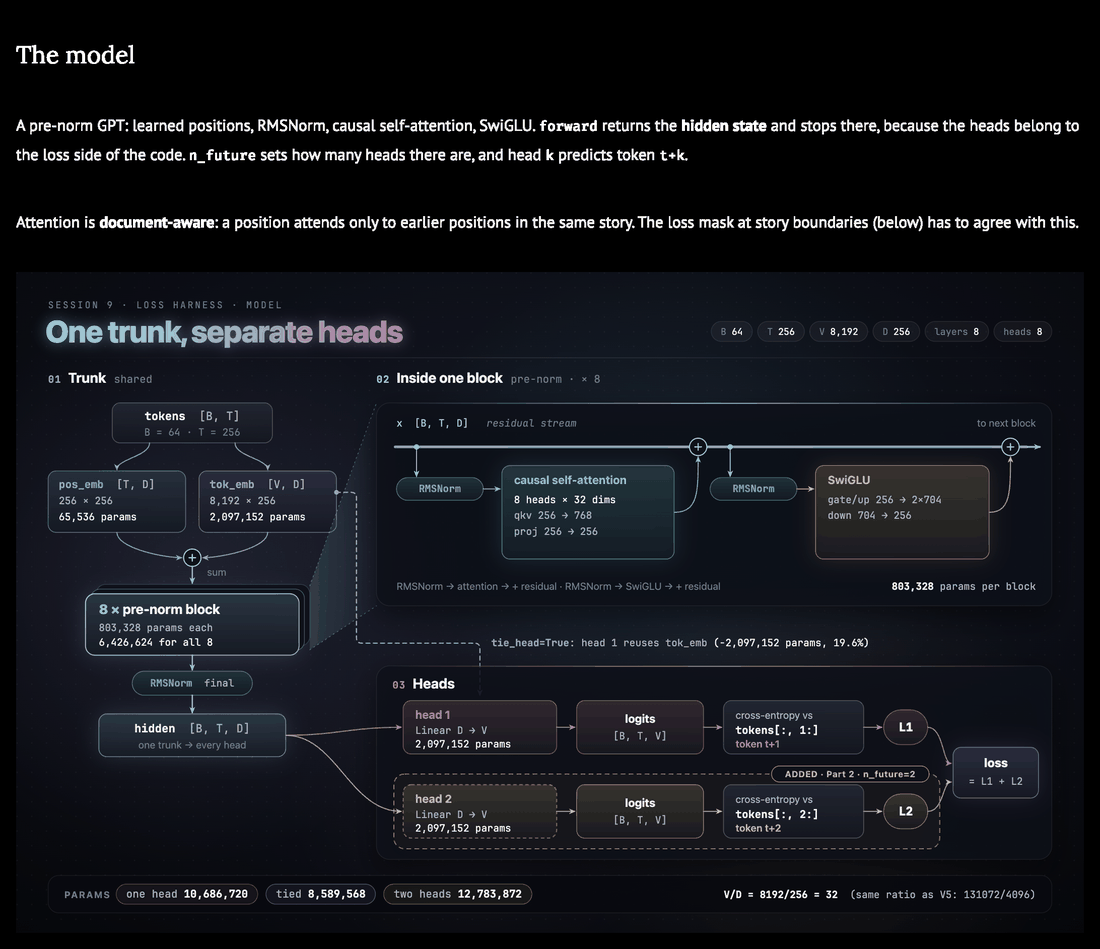

In [ ]:
mo.vstack([mo.md(r"""
## The model

A pre-norm GPT: learned positions, RMSNorm, causal self-attention, SwiGLU. `forward` returns the **hidden state** and stops there, because the heads belong to the loss side of the code. `n_future` sets how many heads there are, and head `k` predicts token `t+k`.

Attention is **document-aware**: a position attends only to earlier positions in the same story. The loss mask at story boundaries (below) has to agree with this.
"""), svg("model")])

In [ ]:
class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.h = c.h
        self.n1, self.n2 = nn.RMSNorm(c.d), nn.RMSNorm(c.d)
        self.qkv = nn.Linear(c.d, 3 * c.d, bias=False)
        self.proj = nn.Linear(c.d, c.d, bias=False)
        self.gate_up = nn.Linear(c.d, 2 * c.ff, bias=False)
        self.down = nn.Linear(c.ff, c.d, bias=False)

    def forward(self, x, mask):
        Bn, T, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(Bn, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        x = x + self.proj(a.transpose(1, 2).reshape(Bn, T, D))
        g, u = self.gate_up(self.n2(x)).chunk(2, dim=-1)
        return x + self.down(F.silu(g) * u)


class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.V, c.d)
        self.pos_emb = nn.Embedding(c.T, c.d)
        self.blocks = nn.ModuleList(Block(c) for _ in range(c.L))
        self.norm = nn.RMSNorm(c.d)
        self.heads = nn.ModuleList(nn.Linear(c.d, c.V, bias=False) for _ in range(c.n_future))
        for name, p in self.named_parameters():
            if p.dim() == 2:
                std = 0.02 / math.sqrt(2 * c.L) if name.endswith(("proj.weight", "down.weight")) else 0.02
                nn.init.normal_(p, 0.0, std)
        if c.tie:
            self.heads[0].weight = self.tok_emb.weight

    def forward(self, tokens, doc=None):
        T = tokens.size(1)
        causal = torch.ones(T, T, dtype=torch.bool, device=tokens.device).tril()
        mask = causal if doc is None else (causal & (doc[:, :, None] == doc[:, None, :]))[:, None]
        x = self.tok_emb(tokens) + self.pos_emb(torch.arange(T, device=tokens.device))
        for blk in self.blocks:
            x = blk(x, mask)
        return self.norm(x)


def n_params(m):
    return sum(p.numel() for p in m.parameters())  # parameters() yields a tied tensor once

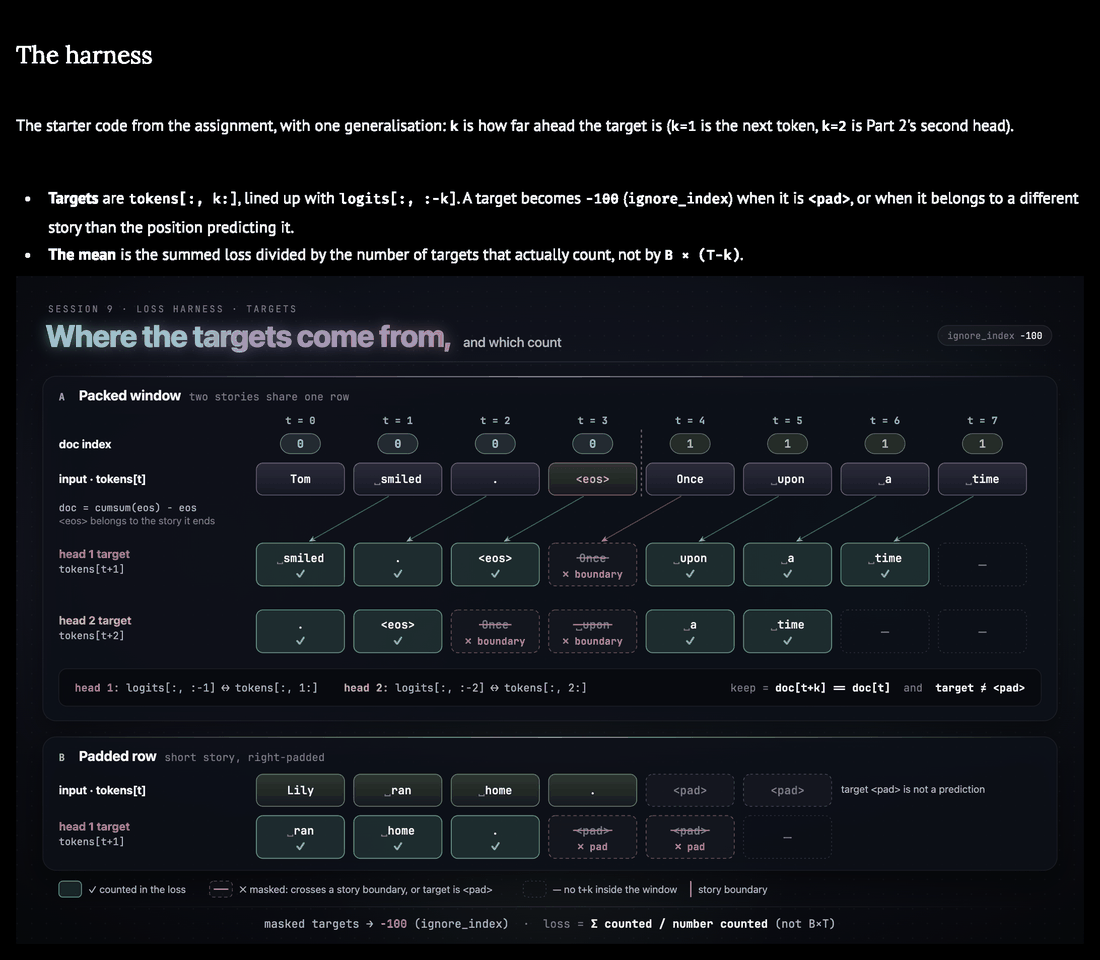

In [ ]:
mo.vstack([mo.md(r"""
## The harness

The starter code from the assignment, with one generalisation: `k` is how far ahead the target is (`k=1` is the next token, `k=2` is Part 2's second head).

* **Targets** are `tokens[:, k:]`, lined up with `logits[:, :-k]`. A target becomes `-100` (`ignore_index`) when it is `<pad>`, or when it belongs to a different story than the position predicting it.
* **The mean** is the summed loss divided by the number of targets that actually count, not by `B × (T-k)`.
"""), svg("targets")])

In [ ]:
IGNORE = -100


def make_targets(tokens, k=1, doc=None, pad_id=None):
    """targets[b, t] = tokens[b, t+k], or IGNORE when that is not a real prediction. Shape [B, T-k]."""
    tgt = tokens[:, k:].clone()
    if pad_id is not None:
        tgt[tgt == pad_id] = IGNORE              # a <pad> target is not a prediction
    if doc is not None:
        tgt[doc[:, k:] != doc[:, :-k]] = IGNORE  # the target lives in the next story
    return tgt


def lm_loss(logits, tokens, k=1, doc=None, pad_id=None):
    """Mean cross-entropy over the counted targets. Returns (loss, number of counted targets)."""
    V = logits.size(-1)
    tgt = make_targets(tokens, k, doc, pad_id)
    total = F.cross_entropy(logits[:, :-k].reshape(-1, V).float(), tgt.reshape(-1),
                            ignore_index=IGNORE, reduction="sum")
    n = (tgt != IGNORE).sum()
    return total / n, int(n)

# Part 1 · The harness, made correct and observable

Every measurement in this part uses one **untrained** model (`model0`: untied, one head) and one fixed validation batch. Items 3 and 4 are run again on the trained models after Part 2.

In [ ]:
torch.manual_seed(0)
model0 = GPT(CFG).to(dev)
xb, docb = get_batch(val_ids, torch.Generator().manual_seed(0))
N = B * (CFG.T - 1)

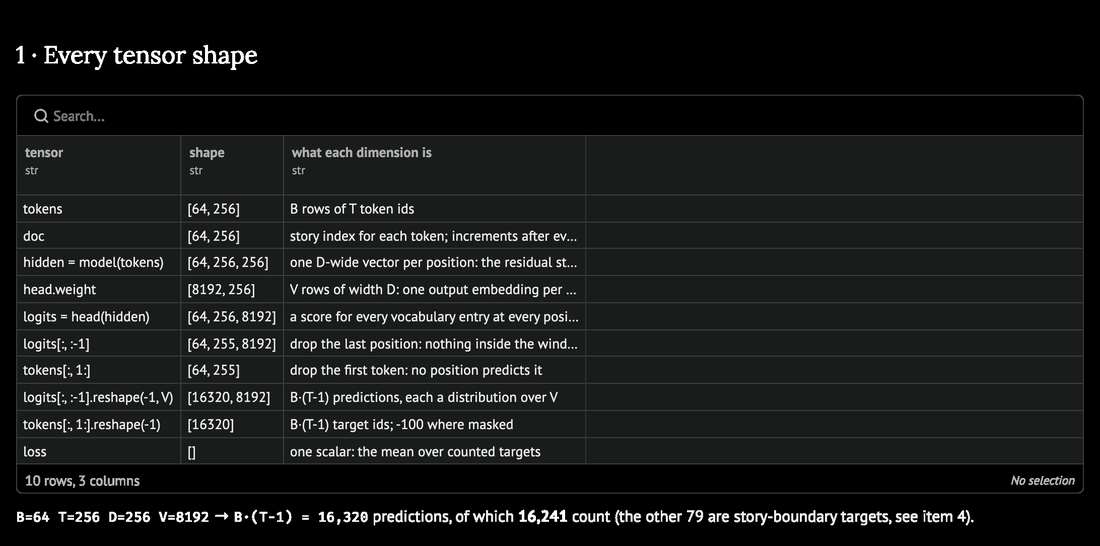

In [ ]:
with torch.no_grad():
    _hidden = model0(xb, docb)
    _logits = model0.heads[0](_hidden)
    _tgt = make_targets(xb, 1, docb, PAD)
    _loss, n_counted = lm_loss(_logits, xb, 1, docb, PAD)

shapes_df = pd.DataFrame([
    ("tokens", xb, "B rows of T token ids"),
    ("doc", docb, "story index for each token; increments after every <eos>"),
    ("hidden = model(tokens)", _hidden, "one D-wide vector per position: the residual stream after the final RMSNorm"),
    ("head.weight", model0.heads[0].weight, "V rows of width D: one output embedding per vocabulary entry"),
    ("logits = head(hidden)", _logits, "a score for every vocabulary entry at every position"),
    ("logits[:, :-1]", _logits[:, :-1], "drop the last position: nothing inside the window follows it"),
    ("tokens[:, 1:]", _tgt, "drop the first token: no position predicts it"),
    ("logits[:, :-1].reshape(-1, V)", _logits[:, :-1].reshape(-1, CFG.V), "B·(T-1) predictions, each a distribution over V"),
    ("tokens[:, 1:].reshape(-1)", _tgt.reshape(-1), "B·(T-1) target ids; -100 where masked"),
    ("loss", _loss, "one scalar: the mean over counted targets"),
], columns=["tensor", "t", "what each dimension is"])
shapes_df.insert(1, "shape", [str(list(t.shape)) for t in shapes_df.pop("t")])
mo.vstack([mo.md("## 1 · Every tensor shape"), shapes_df,
           mo.md(f"`B={B}  T={CFG.T}  D={CFG.d}  V={CFG.V}` → `B·(T-1) = {N:,}` predictions, of which **{n_counted:,}** count "
                 f"(the other {N - n_counted} are story-boundary targets, see item 4).")])

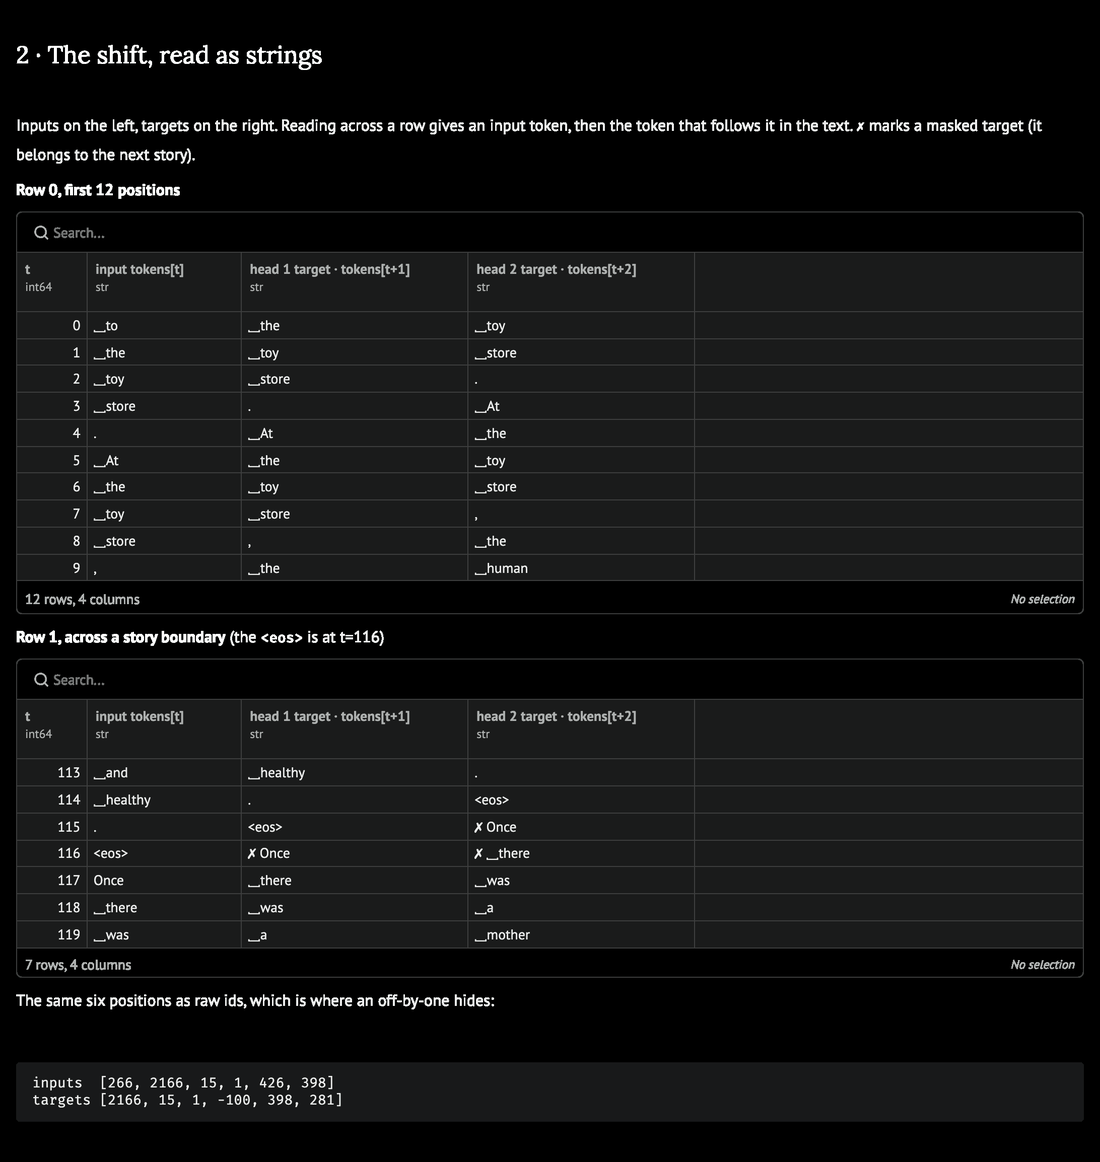

In [ ]:
def shift_table(x, doc, row, start, n):
    t1, t2 = make_targets(x, 1, doc, PAD)[row], make_targets(x, 2, doc, PAD)[row]

    def show(tg, t, k):
        if t >= len(tg):
            return "—"
        return f"✗ {tstr(x[row, t + k])}" if tg[t] == IGNORE else tstr(tg[t])

    return pd.DataFrame([{"t": t, "input tokens[t]": tstr(x[row, t]), "head 1 target · tokens[t+1]": show(t1, t, 1),
                          "head 2 target · tokens[t+2]": show(t2, t, 2)} for t in range(start, start + n)])


_hit = (xb[1:, 3:CFG.T - 4] == EOS).nonzero()[0]
_r, _b = int(_hit[0]) + 1, int(_hit[1]) + 3
mo.vstack([
    mo.md("## 2 · The shift, read as strings\n\nInputs on the left, targets on the right. Reading across a row gives an input token, then the token that follows it in the text. `✗` marks a masked target (it belongs to the next story)."),
    mo.md("**Row 0, first 12 positions**"), shift_table(xb, docb, 0, 0, 12),
    mo.md(f"**Row {_r}, across a story boundary** (the `<eos>` is at t={_b})"), shift_table(xb, docb, _r, _b - 3, 7),
    mo.md(f"""The same six positions as raw ids, which is where an off-by-one hides:

```
inputs  {xb[_r, _b - 3:_b + 3].tolist()}
targets {make_targets(xb, 1, docb, PAD)[_r, _b - 3:_b + 3].tolist()}
```"""),
])

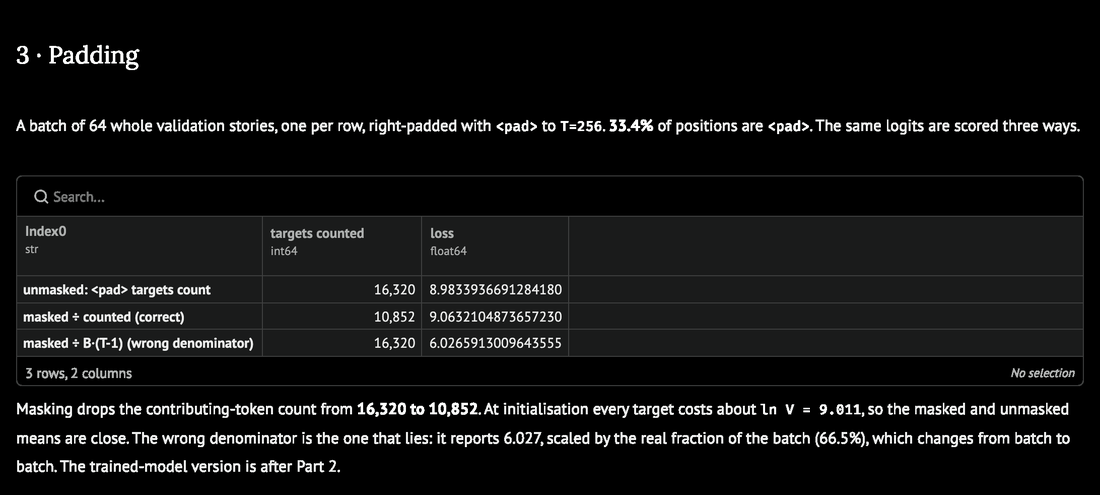

In [ ]:
pad_x = get_padded(val_ids, val_spans, torch.arange(100, 100 + B, device=dev))


@torch.no_grad()
def padding_report(model, x=pad_x):
    with torch.autocast(**AMP):
        lg = model.heads[0](model(x, doc_index(x))).float()
    total_all = F.cross_entropy(lg[:, :-1].reshape(-1, CFG.V), x[:, 1:].reshape(-1), reduction="sum")
    n_all = x[:, 1:].numel()
    masked, n_real = lm_loss(lg, x, 1, None, PAD)
    return {"targets counted": (n_all, n_real, n_all),
            "loss": ((total_all / n_all).item(), masked.item(), (masked * n_real / n_all).item())}


def padding_frame(rep):
    return pd.DataFrame(rep, index=["unmasked: <pad> targets count", "masked ÷ counted (correct)", "masked ÷ B·(T-1) (wrong denominator)"])


pad_untrained = padding_report(model0)
mo.vstack([
    mo.md(f"""## 3 · Padding

A batch of {B} whole validation stories, one per row, right-padded with `<pad>` to `T={CFG.T}`. **{(pad_x == PAD).float().mean().item():.1%}** of positions are `<pad>`. The same logits are scored three ways."""),
    padding_frame(pad_untrained),
    mo.md(f"Masking drops the contributing-token count from **{pad_untrained['targets counted'][0]:,} to {pad_untrained['targets counted'][1]:,}**. "
          f"At initialisation every target costs about `ln V = {math.log(CFG.V):.3f}`, so the masked and unmasked means are close. "
          f"The wrong denominator is the one that lies: it reports {pad_untrained['loss'][2]:.3f}, scaled by the real fraction of the batch "
          f"({pad_untrained['targets counted'][1] / pad_untrained['targets counted'][0]:.1%}), which changes from batch to batch. The trained-model version is after Part 2."),
])

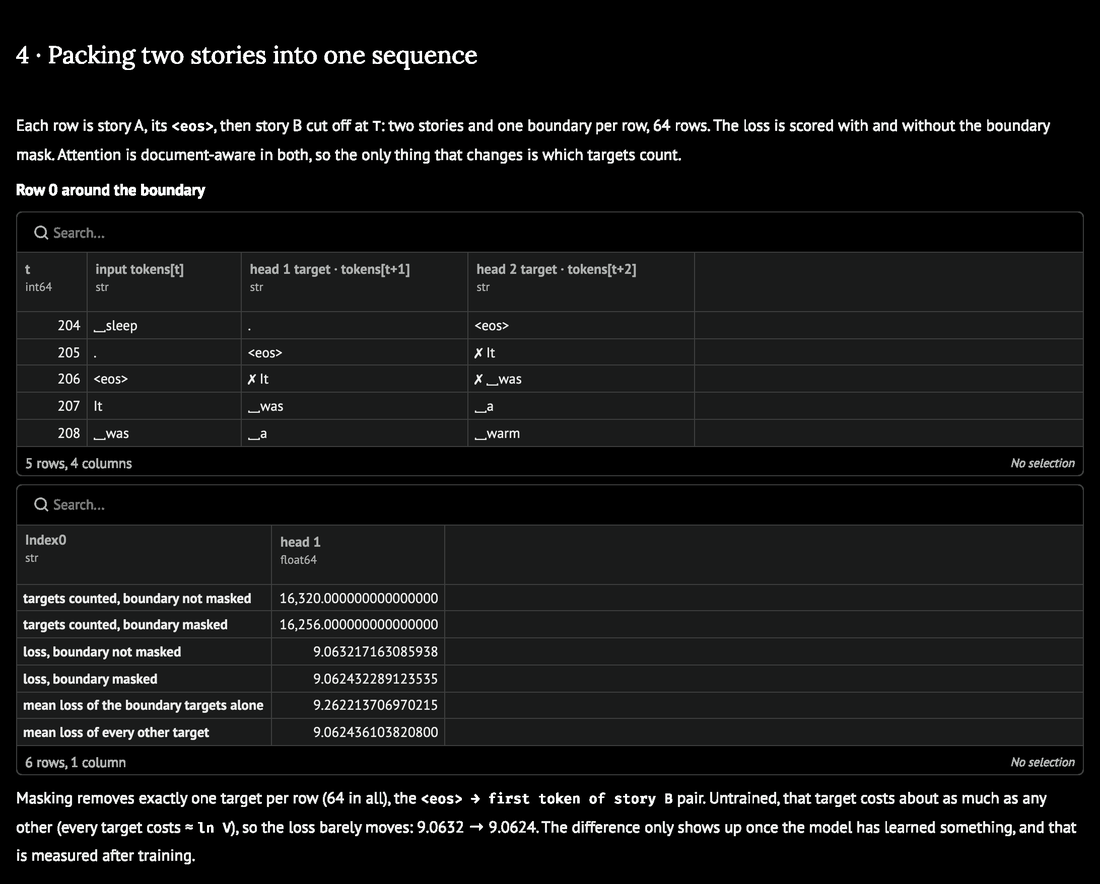

In [ ]:
def packed_batch(docs, bs=B):
    rows, j = [], 0
    while len(rows) < bs:
        a, b_ = docs[j], docs[j + 1]
        j += 2
        if len(a) < CFG.T - 32 and len(a) + len(b_) >= CFG.T:
            rows.append((a + b_)[:CFG.T])
    return torch.tensor(rows, device=dev)


pack_x = packed_batch(val_docs[1000:])
pack_doc = doc_index(pack_x)
assert (pack_doc[:, -1] == 1).all()  # exactly two stories in every row


@torch.no_grad()
def packing_report(model, x=pack_x, doc=pack_doc):
    out = {}
    with torch.autocast(**AMP):
        h = model(x, doc)
    for k, head in enumerate(model.heads, 1):
        with torch.autocast(**AMP):
            lg = head(h).float()
        before, n_b = lm_loss(lg, x, k, None, PAD)
        after, n_a = lm_loss(lg, x, k, doc, PAD)
        per_pos = F.cross_entropy(lg[:, :-k].transpose(1, 2), x[:, k:], reduction="none")  # [B, T-k]
        cross = doc[:, k:] != doc[:, :-k]
        out[f"head {k}"] = {"targets counted, boundary not masked": n_b, "targets counted, boundary masked": n_a,
                            "loss, boundary not masked": before.item(), "loss, boundary masked": after.item(),
                            "mean loss of the boundary targets alone": per_pos[cross].mean().item(),
                            "mean loss of every other target": per_pos[~cross].mean().item()}
    return pd.DataFrame(out)


pack_untrained = packing_report(model0)
_b0 = int((pack_x[0] == EOS).nonzero()[0])
mo.vstack([
    mo.md(f"""## 4 · Packing two stories into one sequence

Each row is story A, its `<eos>`, then story B cut off at `T`: two stories and one boundary per row, {B} rows. The loss is scored with and without the boundary mask. Attention is document-aware in both, so the only thing that changes is which targets count."""),
    mo.md("**Row 0 around the boundary**"), shift_table(pack_x, pack_doc, 0, _b0 - 2, 5),
    pack_untrained,
    mo.md(f"Masking removes exactly one target per row ({B} in all), the `<eos> → first token of story B` pair. "
          f"Untrained, that target costs about as much as any other (every target costs ≈ `ln V`), so the loss barely moves: "
          f"{pack_untrained.loc['loss, boundary not masked', 'head 1']:.4f} → {pack_untrained.loc['loss, boundary masked', 'head 1']:.4f}. "
          "The difference only shows up once the model has learned something, and that is measured after training."),
])

In [ ]:
@torch.no_grad()
def evaluate(model, ids=val_ids, n_batches=20, seed=123):
    """Per-head mean loss (masked correctly) and top-1 accuracy on fixed validation windows."""
    g = torch.Generator().manual_seed(seed)
    nh = len(model.heads)
    tot, hit, cnt = (torch.zeros(nh, device=dev) for _ in range(3))
    for _ in range(n_batches):
        x, doc = get_batch(ids, g)
        with torch.autocast(**AMP):
            h = model(x, doc)
        for k, head in enumerate(model.heads, 1):
            with torch.autocast(**AMP):
                lg = head(h).float()[:, :-k]
            tgt = make_targets(x, k, doc, PAD)
            keep = tgt != IGNORE
            tot[k - 1] += F.cross_entropy(lg.reshape(-1, CFG.V), tgt.reshape(-1), ignore_index=IGNORE, reduction="sum")
            hit[k - 1] += (lg.argmax(-1)[keep] == tgt[keep]).sum()
            cnt[k - 1] += keep.sum()
    return (tot / cnt).tolist(), (hit / cnt).tolist()


(l0,), _ = evaluate(model0)
ppl0 = math.exp(l0)
with torch.no_grad():
    _std = model0.heads[0](model0(xb, docb)).float().std().item()
assert abs(l0 - math.log(CFG.V)) < 0.25, "untrained loss is far from ln V: inspect the harness before training"
mo.md(f"""## 5 · Perplexity of the untrained model

| | value |
|---|---:|
| untrained validation loss | **{l0:.4f}** nats |
| `ln V = ln {CFG.V}` | {math.log(CFG.V):.4f} |
| untrained perplexity `exp(loss)` | **{ppl0:,.0f}** |
| vocabulary size `V` | {CFG.V:,} |
| ratio | {ppl0 / CFG.V:.3f} |

The untrained model sits at {ppl0 / CFG.V:.1%} of `V`, which is what a near-uniform guess over the vocabulary looks like. It is slightly above `V` because the logits at init are not exactly zero: their std is {_std:.3f}, and random Gaussian logits with std σ give perplexity ≈ `V·exp(σ²/2)` = {CFG.V * math.exp(_std ** 2 / 2):,.0f}. The `assert` in this cell stops the notebook if the loss is not near `ln V`.
""")

<span class="markdown prose dark:prose-invert contents"><h2 id="5-perplexity-of-the-untrained-model">5 · Perplexity of the untrained model</h2>
<table>
<thead>
<tr>
<th></th>
<th style="text-align: right;">value</th>
</tr>
</thead>
<tbody>
<tr>
<td>untrained validation loss</td>
<td style="text-align: right;"><strong>9.0702</strong> nats</td>
</tr>
<tr>
<td><code>ln V = ln 8192</code></td>
<td style="text-align: right;">9.0109</td>
</tr>
<tr>
<td>untrained perplexity <code>exp(loss)</code></td>
<td style="text-align: right;"><strong>8,693</strong></td>
</tr>
<tr>
<td>vocabulary size <code>V</code></td>
<td style="text-align: right;">8,192</td>
</tr>
<tr>
<td>ratio</td>
<td style="text-align: right;">1.061</td>
</tr>
</tbody>
</table>
<span class="paragraph">The untrained model sits at 106.1% of <code>V</code>, which is what a near-uniform guess over the vocabulary looks like. It is slightly above <code>V</code> because the logits at init are not exactly zero: their std is 0.321, and random Gaussian logits with std σ give perplexity ≈ <code>V·exp(σ²/2)</code> = 8,624. The <code>assert</code> in this cell stops the notebook if the loss is not near <code>ln V</code>.</span></span>

In [ ]:
_tied, _untied, _two = GPT(replace(CFG, tie=True)), GPT(CFG), GPT(replace(CFG, n_future=2))
assert _tied.heads[0].weight.data_ptr() == _tied.tok_emb.weight.data_ptr()
head_params = CFG.V * CFG.d
counts = {"tied": n_params(_tied), "untied": n_params(_untied), "untied + head 2": n_params(_two), "block": n_params(_untied.blocks[0])}
mo.md(f"""## 6 · Tied vs untied head

| configuration | parameters |
|---|---:|
| tied (head 1 *is* `tok_emb`) | **{counts['tied']:,}** |
| untied | **{counts['untied']:,}** |
| untied + head 2 (Part 2) | {counts['untied + head 2']:,} |

One head is `V·D = {CFG.V}·{CFG.d} = {head_params:,}` parameters. Tying saves exactly that: **{head_params / counts['untied']:.1%}** of the untied model.
One head is also {head_params / counts['block']:.1f}× a whole transformer block ({counts['block']:,}), so the output side matters even at this size. Every other run in this notebook is untied: Part 2's second head needs its own matrix anyway, and V5 has no input table to tie to.
""")

<span class="markdown prose dark:prose-invert contents"><h2 id="6-tied-vs-untied-head">6 · Tied vs untied head</h2>
<table>
<thead>
<tr>
<th>configuration</th>
<th style="text-align: right;">parameters</th>
</tr>
</thead>
<tbody>
<tr>
<td>tied (head 1 <em>is</em> <code>tok_emb</code>)</td>
<td style="text-align: right;"><strong>8,589,568</strong></td>
</tr>
<tr>
<td>untied</td>
<td style="text-align: right;"><strong>10,686,720</strong></td>
</tr>
<tr>
<td>untied + head 2 (Part 2)</td>
<td style="text-align: right;">12,783,872</td>
</tr>
</tbody>
</table>
<span class="paragraph">One head is <code>V·D = 8192·256 = 2,097,152</code> parameters. Tying saves exactly that: <strong>19.6%</strong> of the untied model.
One head is also 2.6× a whole transformer block (803,328), so the output side matters even at this size. Every other run in this notebook is untied: Part 2's second head needs its own matrix anyway, and V5 has no input table to tie to.</span></span>

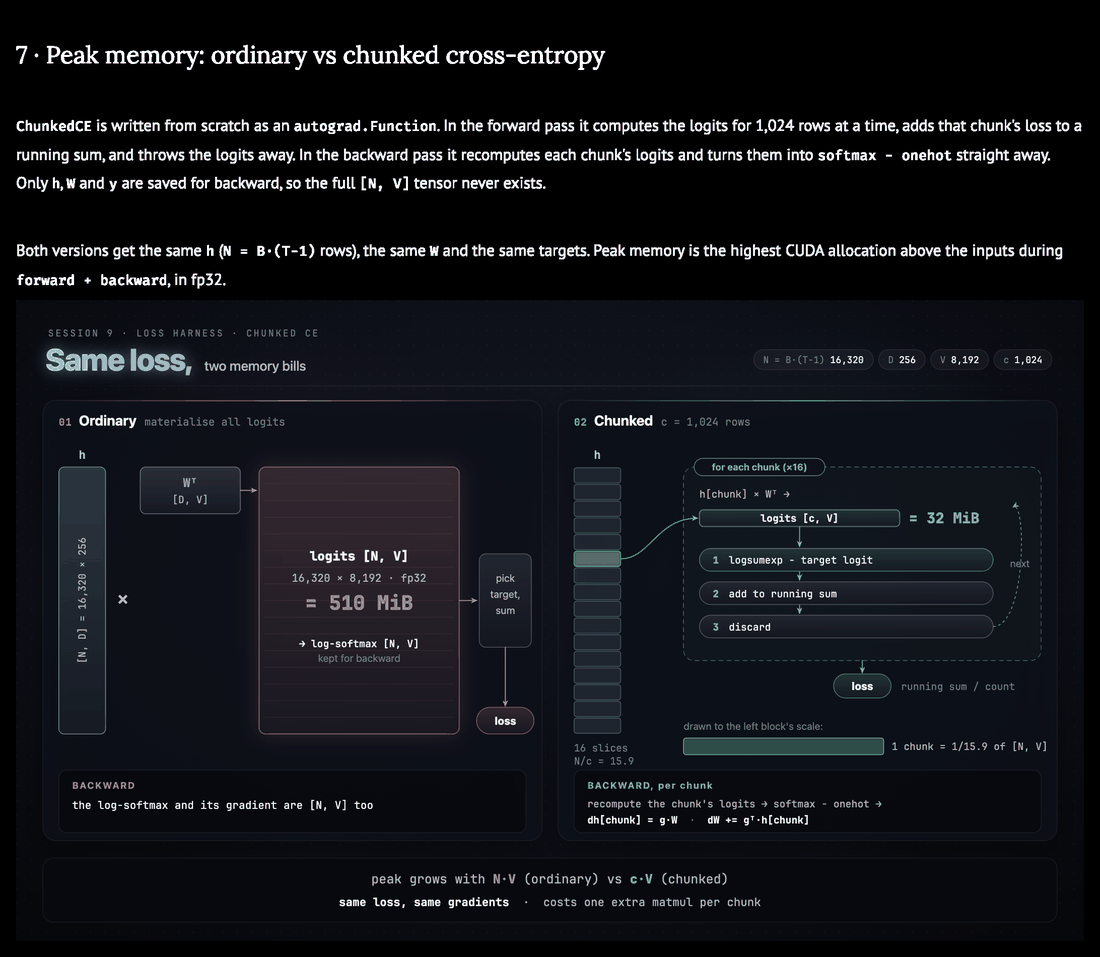

In [ ]:
mo.vstack([mo.md(r"""
## 7 · Peak memory: ordinary vs chunked cross-entropy

`ChunkedCE` is written from scratch as an `autograd.Function`. In the forward pass it computes the logits for 1,024 rows at a time, adds that chunk's loss to a running sum, and throws the logits away. In the backward pass it recomputes each chunk's logits and turns them into `softmax − onehot` straight away. Only `h`, `W` and `y` are saved for backward, so the full `[N, V]` tensor never exists.

Both versions get the same `h` (`N = B·(T-1)` rows), the same `W` and the same targets. Peak memory is the highest CUDA allocation above the inputs during `forward + backward`, in fp32.
"""), svg("chunked-ce")])

In [ ]:
class ChunkedCE(torch.autograd.Function):
    @staticmethod
    def forward(ctx, h, W, y, chunk):
        total = torch.zeros((), device=h.device, dtype=torch.float32)
        for i in range(0, h.size(0), chunk):
            z = (h[i:i + chunk] @ W.T).float()                  # [chunk, V], freed next iteration
            total += F.cross_entropy(z, y[i:i + chunk], ignore_index=IGNORE, reduction="sum")
        n = (y != IGNORE).sum().clamp(min=1)
        ctx.save_for_backward(h, W, y, n)
        ctx.chunk = chunk
        return total / n

    @staticmethod
    def backward(ctx, g):
        h, W, y, n = ctx.saved_tensors
        dh, dW = torch.empty_like(h), torch.zeros_like(W)
        for i in range(0, h.size(0), ctx.chunk):
            hc, yc = h[i:i + ctx.chunk], y[i:i + ctx.chunk]
            p = torch.softmax((hc @ W.T).float(), dim=-1)       # recompute this chunk's logits
            keep = yc != IGNORE
            p[keep, yc[keep]] -= 1.0                             # softmax - onehot
            p[~keep] = 0.0
            p = (p * (g / n)).to(h.dtype)
            dh[i:i + ctx.chunk] = p @ W
            dW += p.T @ hc
        return dh, dW, None, None


def chunked_ce(h, W, y, chunk=1024):
    return ChunkedCE.apply(h, W, y, chunk)


def ordinary_ce(h, W, y):
    return F.cross_entropy(h @ W.T, y, ignore_index=IGNORE)


def ce_inputs(n, seed=0):
    g = torch.Generator(device=dev).manual_seed(seed)
    h = torch.randn(n, CFG.d, device=dev, generator=g).requires_grad_()
    W = (0.02 * torch.randn(CFG.V, CFG.d, device=dev, generator=g)).requires_grad_()
    y = torch.randint(0, CFG.V, (n,), device=dev, generator=g)
    y[::17] = IGNORE  # some masked targets, so the ignore path is exercised too
    return h, W, y


def measure(fn, h, W, y):
    """(loss, peak MiB above the inputs, seconds, dh, dW) for one forward + backward."""
    h.grad = W.grad = None
    torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated()
    t = time.time()
    loss = fn(h, W, y)
    loss.backward()
    torch.cuda.synchronize()
    return loss.item(), (torch.cuda.max_memory_allocated() - base) / 2**20, time.time() - t, h.grad.clone(), W.grad.clone()


_h, _W, _y = ce_inputs(N)
measure(ordinary_ce, _h, _W, _y); measure(chunked_ce, _h, _W, _y)  # warm-up
_lo, _po, _to, _gho, _gWo = measure(ordinary_ce, _h, _W, _y)
_lc, _pc, _tc, _ghc, _gWc = measure(chunked_ce, _h, _W, _y)
_dl, _dh, _dW = abs(_lo - _lc), (_gho - _ghc).abs().max().item(), (_gWo - _gWc).abs().max().item()
assert _dl < 1e-4 and _dh < 1e-5 and _dW < 1e-5
mem = {"ordinary MiB": _po, "chunked MiB": _pc, "ratio": _po / _pc, "ordinary ms": _to * 1e3, "chunked ms": _tc * 1e3}
del _h, _W, _y, _gho, _gWo, _ghc, _gWc

mo.md(f"""**At this notebook's configuration** · `N = B·(T-1) = {N:,}` rows, `D={CFG.d}`, `V={CFG.V:,}`. One fp32 `[N, V]` logits tensor is {N * CFG.V * 4 / 2**20:,.0f} MiB.

| | loss | peak memory | time |
|---|---:|---:|---:|
| ordinary `F.cross_entropy(h @ W.T, y)` | {_lo:.6f} | **{_po:,.1f} MiB** | {_to * 1e3:.1f} ms |
| chunked, 1,024 rows per chunk | {_lc:.6f} | **{_pc:,.1f} MiB** | {_tc * 1e3:.1f} ms |
| ratio | | **{_po / _pc:.1f}× less** | {_tc / _to:.2f}× the time |

Same objective: `|Δloss| = {_dl:.1e}`, `max|Δ dh| = {_dh:.1e}`, `max|Δ dW| = {_dW:.1e}`. The ordinary path keeps about three `[N, V]`-sized buffers alive at once (logits, the saved log-softmax, and their gradient). The chunked path keeps one `[1024, V]` chunk plus a few softmax temporaries.
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><strong>At this notebook's configuration</strong> · <code>N = B·(T-1) = 16,320</code> rows, <code>D=256</code>, <code>V=8,192</code>. One fp32 <code>[N, V]</code> logits tensor is 510 MiB.</span>
<table>
<thead>
<tr>
<th></th>
<th style="text-align: right;">loss</th>
<th style="text-align: right;">peak memory</th>
<th style="text-align: right;">time</th>
</tr>
</thead>
<tbody>
<tr>
<td>ordinary <code>F.cross_entropy(h @ W.T, y)</code></td>
<td style="text-align: right;">9.061922</td>
<td style="text-align: right;"><strong>1,530.0 MiB</strong></td>
<td style="text-align: right;">5.9 ms</td>
</tr>
<tr>
<td>chunked, 1,024 rows per chunk</td>
<td style="text-align: right;">9.061922</td>
<td style="text-align: right;"><strong>119.9 MiB</strong></td>
<td style="text-align: right;">10.5 ms</td>
</tr>
<tr>
<td>ratio</td>
<td style="text-align: right;"></td>
<td style="text-align: right;"><strong>12.8× less</strong></td>
<td style="text-align: right;">1.76× the time</td>
</tr>
</tbody>
</table>
<span class="paragraph">Same objective: <code>|Δloss| = 0.0e+00</code>, <code>max|Δ dh| = 1.8e-11</code>, <code>max|Δ dW| = 2.8e-10</code>. The ordinary path keeps about three <code>[N, V]</code>-sized buffers alive at once (logits, the saved log-softmax, and their gradient). The chunked path keeps one <code>[1024, V]</code> chunk plus a few softmax temporaries.</span></span>

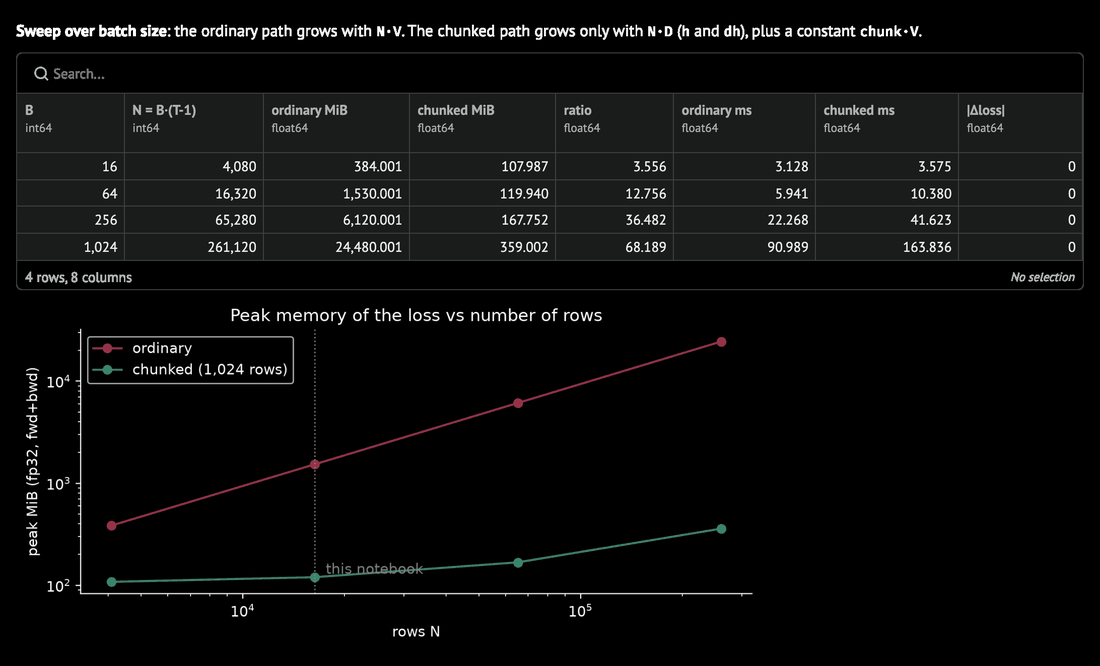

In [ ]:
_rows = []
for _bs in [16, 64, 256, 1024]:
    _n = _bs * (CFG.T - 1)
    _h, _W, _y = ce_inputs(_n)
    _lo, _po, _to, *_r1 = measure(ordinary_ce, _h, _W, _y)
    _lc, _pc, _tc, *_r2 = measure(chunked_ce, _h, _W, _y)
    _rows.append({"B": _bs, "N = B·(T-1)": _n, "ordinary MiB": _po, "chunked MiB": _pc, "ratio": _po / _pc,
                  "ordinary ms": _to * 1e3, "chunked ms": _tc * 1e3, "|Δloss|": abs(_lo - _lc)})
    del _h, _W, _y, _r1, _r2
sweep_df = pd.DataFrame(_rows)

_fig, _ax = plt.subplots(figsize=(7.5, 3.6))
_ax.loglog(sweep_df["N = B·(T-1)"], sweep_df["ordinary MiB"], "o-", color="#e11d48", label="ordinary")
_ax.loglog(sweep_df["N = B·(T-1)"], sweep_df["chunked MiB"], "o-", color="#059669", label="chunked (1,024 rows)")
_ax.axvline(N, color="gray", ls=":", lw=1)
_ax.text(N * 1.08, sweep_df["chunked MiB"].min() * 1.2, "this notebook", color="gray")
_ax.set(xlabel="rows N", ylabel="peak MiB (fp32, fwd+bwd)", title="Peak memory of the loss vs number of rows")
_ax.legend()
_fig.tight_layout()
mo.vstack([mo.md("**Sweep over batch size**: the ordinary path grows with `N·V`. The chunked path grows only with `N·D` (`h` and `dh`), plus a constant `chunk·V`."),
           sweep_df.round(3), _fig])

# Training: guard runs, then one head vs two

* **Guard 1, the off-by-one.** The same model trained on the *unshifted* harness (`logits` against `tokens`, no shift) next to the correct one, for 300 steps.
* **Guard 2, padding counted in training.** Two runs on padded batches, 800 steps each. One counts the `<pad>` targets, the other masks them. Both are then scored on real tokens only.
* **The real runs.** `baseline` has one head (`t+1`) and its loss is `L1`. `mtp` has two heads (`t+1`, `t+2`) on the same trunk, and its loss is `L1 + L2`. Both use the same initialisation seed and see the same batches in the same order.

In [ ]:
def lr_at(step, steps, warm=100):
    if step < warm:
        return LR * (step + 1) / warm
    return LR * (0.1 + 0.45 * (1 + math.cos(math.pi * (step - warm) / max(1, steps - warm))))


def train(n_future, steps=STEPS, seed=0, batch="packed", count_pad=False, loss_fn=None, log_every=25, eval_every=250):
    torch.manual_seed(seed)
    model = GPT(replace(CFG, n_future=n_future)).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1, fused=dev == "cuda")
    gen = torch.Generator().manual_seed(seed)  # identical batches across runs with the same seed
    hist = {"step": [], "train": [], "val_step": [], "val": [], "val_acc": []}
    acc, t0 = None, time.time()
    for step in range(steps):
        for grp in opt.param_groups:
            grp["lr"] = lr_at(step, steps)
        if batch == "packed":
            x, doc = get_batch(train_ids, gen)
        else:
            x = get_padded(train_ids, train_spans, torch.randint(len(train_spans[0]), (B,), generator=gen).to(dev))
            doc = doc_index(x)
        with torch.autocast(**AMP):
            h = model(x, doc)
            if loss_fn is not None:
                losses = loss_fn(model, h, x).reshape(1)
            else:
                losses = torch.stack([lm_loss(head(h), x, k, doc, None if count_pad else PAD)[0]
                                      for k, head in enumerate(model.heads, 1)])
        losses.sum().backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
        acc = losses.detach() if acc is None else acc + losses.detach()
        if (step + 1) % log_every == 0:
            hist["step"].append(step + 1)
            hist["train"].append((acc / log_every).tolist())
            acc = None
        if eval_every and ((step + 1) % eval_every == 0 or step == 0):
            vl, va = evaluate(model)
            hist["val_step"].append(step + 1); hist["val"].append(vl); hist["val_acc"].append(va)
    hist["seconds"] = time.time() - t0
    return model, hist


def smooth(a, w=4):
    a = np.asarray(a, dtype=float)
    return np.convolve(np.pad(a, (w - 1, 0), mode="edge"), np.ones(w) / w, mode="valid")

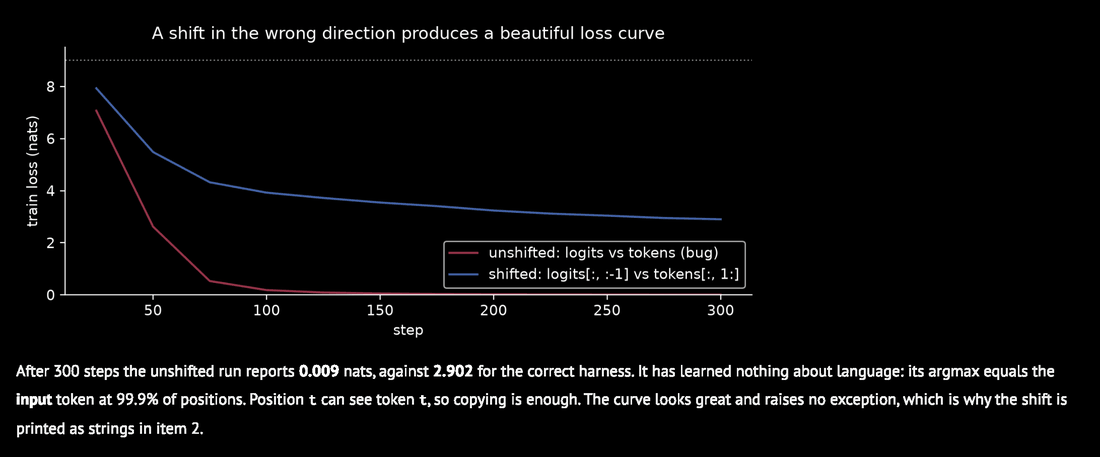

In [ ]:
def unshifted_loss(model, h, x):
    lg = model.heads[0](h)
    return F.cross_entropy(lg.reshape(-1, CFG.V).float(), x.reshape(-1))  # BUG: the target is the input itself


_m_bug, guard_bug = train(1, steps=300, loss_fn=unshifted_loss, eval_every=0)
_m_ok, guard_ok = train(1, steps=300, eval_every=0)
with torch.no_grad(), torch.autocast(**AMP):
    _p = _m_bug.heads[0](_m_bug(xb, docb)).argmax(-1)
copy_rate = (_p == xb).float().mean().item()
del _m_bug, _m_ok

_fig, _ax = plt.subplots(figsize=(7.5, 3.4))
_ax.plot(guard_bug["step"], [v[0] for v in guard_bug["train"]], color="#e11d48", label="unshifted: logits vs tokens (bug)")
_ax.plot(guard_ok["step"], [v[0] for v in guard_ok["train"]], color="#2563eb", label="shifted: logits[:, :-1] vs tokens[:, 1:]")
_ax.axhline(math.log(CFG.V), color="gray", ls=":", lw=1)
_ax.set(xlabel="step", ylabel="train loss (nats)", title="A shift in the wrong direction produces a beautiful loss curve", ylim=(0, 9.5))
_ax.legend()
_fig.tight_layout()
mo.vstack([_fig, mo.md(
    f"After 300 steps the unshifted run reports **{guard_bug['train'][-1][0]:.3f}** nats, against **{guard_ok['train'][-1][0]:.3f}** for the correct harness. "
    f"It has learned nothing about language: its argmax equals the **input** token at {copy_rate:.1%} of positions. Position `t` can see token `t`, so copying is enough. "
    "The curve looks great and raises no exception, which is why the shift is printed as strings in item 2.")])

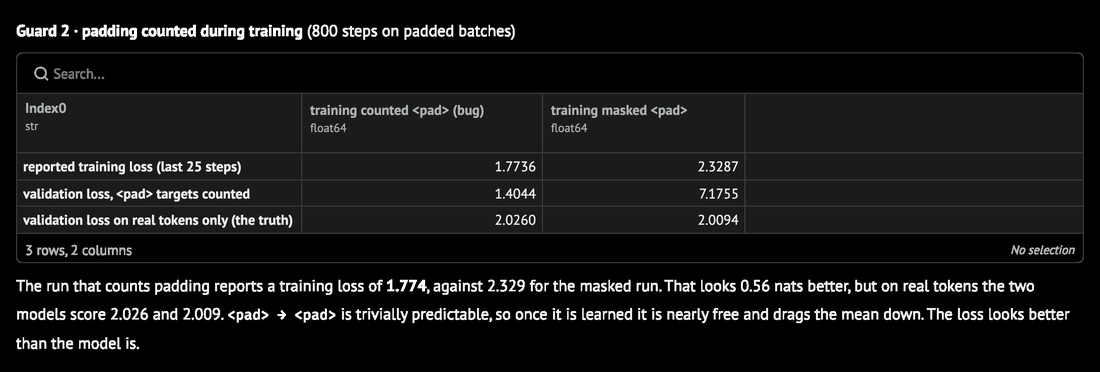

In [ ]:
_m_cnt, pad_hist_cnt = train(1, steps=800, batch="padded", count_pad=True, eval_every=0)
_m_msk, pad_hist_msk = train(1, steps=800, batch="padded", count_pad=False, eval_every=0)
_rep_cnt, _rep_msk = padding_report(_m_cnt), padding_report(_m_msk)
pad_train_df = pd.DataFrame({
    "training counted <pad> (bug)": [pad_hist_cnt["train"][-1][0], _rep_cnt["loss"][0], _rep_cnt["loss"][1]],
    "training masked <pad>": [pad_hist_msk["train"][-1][0], _rep_msk["loss"][0], _rep_msk["loss"][1]],
}, index=["reported training loss (last 25 steps)", "validation loss, <pad> targets counted", "validation loss on real tokens only (the truth)"])
del _m_cnt, _m_msk
mo.vstack([mo.md("**Guard 2 · padding counted during training** (800 steps on padded batches)"), pad_train_df.round(4), mo.md(
    f"The run that counts padding reports a training loss of **{pad_train_df.iloc[0, 0]:.3f}**, against {pad_train_df.iloc[0, 1]:.3f} for the masked run. That looks "
    f"{pad_train_df.iloc[0, 1] - pad_train_df.iloc[0, 0]:.2f} nats better, but on real tokens the two models score {pad_train_df.iloc[2, 0]:.3f} and {pad_train_df.iloc[2, 1]:.3f}. "
    "`<pad> → <pad>` is trivially predictable, so once it is learned it is nearly free and drags the mean down. The loss looks better than the model is.")])

In [ ]:
baseline, hist_base = train(1)
mo.md(f"`baseline` (1 head) trained for {STEPS:,} steps in {hist_base['seconds']:.0f}s · final validation `L1 = {hist_base['val'][-1][0]:.4f}`")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><code>baseline</code> (1 head) trained for 5,000 steps in 90s · final validation <code>L1 = 1.8573</code></span></span>

In [ ]:
mtp, hist_mtp = train(2)
mo.md(f"`mtp` (2 heads) trained for {STEPS:,} steps in {hist_mtp['seconds']:.0f}s · final validation `L1 = {hist_mtp['val'][-1][0]:.4f}`, `L2 = {hist_mtp['val'][-1][1]:.4f}`")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><code>mtp</code> (2 heads) trained for 5,000 steps in 118s · final validation <code>L1 = 1.8978</code>, <code>L2 = 2.8953</code></span></span>

# Part 2 · One extra head

Head 2 is a second `Linear(D, V)` reading the **same final hidden state** as head 1. Its targets are `tokens[:, 2:]` against `logits[:, :-2]`, with the same `<pad>` and story-boundary masking. A head-2 target is dropped when `t+2` falls in the next story, which covers twice as many positions as head 1's boundary mask. The training loss is `L1 + L2`.

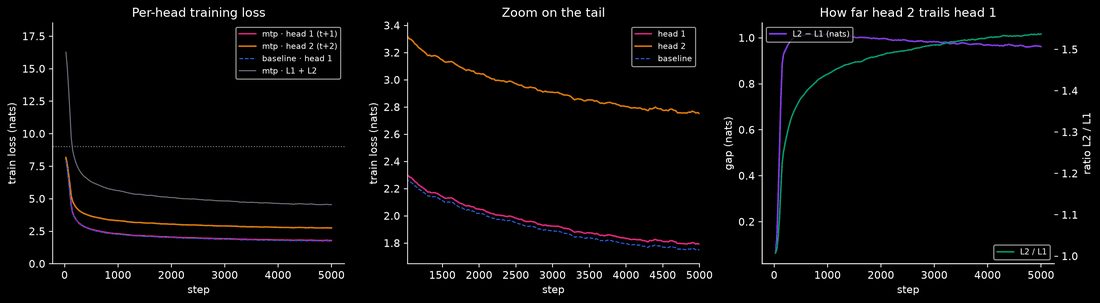

In [ ]:
_st = np.array(hist_mtp["step"])
_tr = np.array(hist_mtp["train"])
_L1, _L2 = smooth(_tr[:, 0]), smooth(_tr[:, 1])
_Lb = smooth(np.array(hist_base["train"])[:, 0])

_fig, _ax = plt.subplots(1, 3, figsize=(15, 4.2))
_ax[0].plot(_st, _L1, color="#db2777", label="mtp · head 1 (t+1)")
_ax[0].plot(_st, _L2, color="#d97706", label="mtp · head 2 (t+2)")
_ax[0].plot(_st, _Lb, color="#2563eb", ls="--", lw=1, label="baseline · head 1")
_ax[0].plot(_st, _L1 + _L2, color="#6b7280", lw=1, label="mtp · L1 + L2")
_ax[0].axhline(math.log(CFG.V), color="gray", ls=":", lw=1)
_ax[0].set(xlabel="step", ylabel="train loss (nats)", title="Per-head training loss", ylim=(0, 2 * math.log(CFG.V) + 0.5))
_ax[0].legend(fontsize=8)
_ax[1].plot(_st, _L1, color="#db2777", label="head 1")
_ax[1].plot(_st, _L2, color="#d97706", label="head 2")
_ax[1].plot(_st, _Lb, color="#2563eb", ls="--", lw=1, label="baseline")
_ax[1].set(xlabel="step", ylabel="train loss (nats)", title="Zoom on the tail", xlim=(_st[len(_st) // 5], _st[-1]))
_ax[1].set_ylim(min(_L1[len(_st) // 5:].min(), _Lb[len(_st) // 5:].min()) - 0.1, _L2[len(_st) // 5:].max() + 0.1)
_ax[1].legend(fontsize=8)
_ax[2].plot(_st, _L2 - _L1, color="#7c3aed", label="L2 − L1 (nats)")
_ax[2].set(xlabel="step", ylabel="gap (nats)", title="How far head 2 trails head 1")
_axb = _ax[2].twinx()
_axb.plot(_st, _L2 / _L1, color="#059669", label="L2 / L1")
_axb.set_ylabel("ratio L2 / L1")
_ax[2].legend(loc="upper left", fontsize=8); _axb.legend(loc="lower right", fontsize=8)
_fig.tight_layout()
_fig

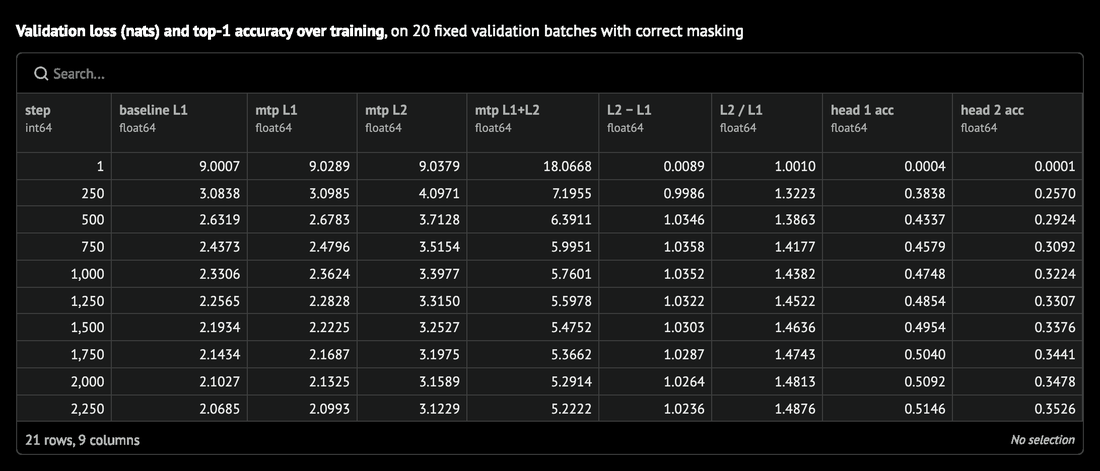

In [ ]:
_vb, _vm = np.array(hist_base["val"]), np.array(hist_mtp["val"])
_ab, _am = np.array(hist_base["val_acc"]), np.array(hist_mtp["val_acc"])
val_table = pd.DataFrame({"step": hist_mtp["val_step"], "baseline L1": _vb[:, 0], "mtp L1": _vm[:, 0], "mtp L2": _vm[:, 1],
                          "mtp L1+L2": _vm.sum(1), "L2 − L1": _vm[:, 1] - _vm[:, 0], "L2 / L1": _vm[:, 1] / _vm[:, 0],
                          "head 1 acc": _am[:, 0], "head 2 acc": _am[:, 1]})
mo.vstack([mo.md("**Validation loss (nats) and top-1 accuracy over training**, on 20 fixed validation batches with correct masking"), val_table.round(4)])

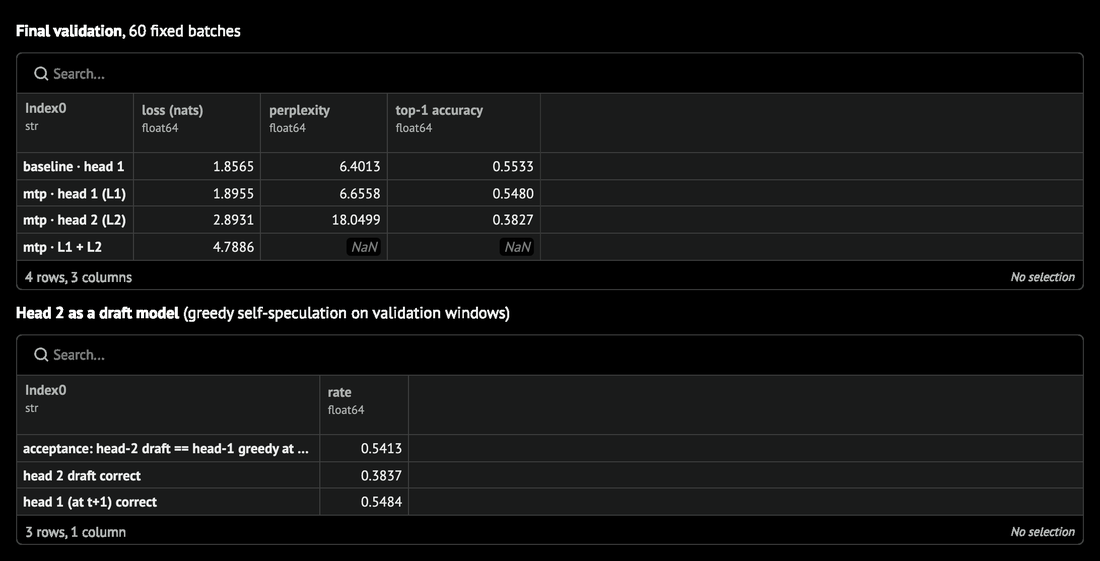

In [ ]:
@torch.no_grad()
def draft_stats(model, n_batches=40, seed=321):
    """Head 2 at t drafts token t+2. Head 1 at t+1 verifies it (greedy). Acceptance = how often they agree."""
    g = torch.Generator().manual_seed(seed)
    agree = right2 = right1 = cnt = 0
    for _ in range(n_batches):
        x, doc = get_batch(val_ids, g)
        with torch.autocast(**AMP):
            h = model(x, doc)
            p1, p2 = model.heads[0](h).argmax(-1), model.heads[1](h).argmax(-1)
        T = x.size(1)
        ok = doc[:, 2:] == doc[:, :-2]                       # t and t+2 in the same story
        draft, verify, truth = p2[:, :T - 2], p1[:, 1:T - 1], x[:, 2:]
        agree += ((draft == verify) & ok).sum().item()
        right2 += ((draft == truth) & ok).sum().item()
        right1 += ((verify == truth) & ok).sum().item()
        cnt += ok.sum().item()
    return {"acceptance: head-2 draft == head-1 greedy at t+1": agree / cnt,
            "head 2 draft correct": right2 / cnt, "head 1 (at t+1) correct": right1 / cnt}


(bl1,), (ba1,) = evaluate(baseline, n_batches=60)
(ml1, ml2), (ma1, ma2) = evaluate(mtp, n_batches=60)
drafts = draft_stats(mtp)
final_df = pd.DataFrame({
    "loss (nats)": [bl1, ml1, ml2, ml1 + ml2],
    "perplexity": [math.exp(bl1), math.exp(ml1), math.exp(ml2), float("nan")],
    "top-1 accuracy": [ba1, ma1, ma2, float("nan")],
}, index=["baseline · head 1", "mtp · head 1 (L1)", "mtp · head 2 (L2)", "mtp · L1 + L2"])
mo.vstack([mo.md("**Final validation**, 60 fixed batches"), final_df.round(4),
           mo.md("**Head 2 as a draft model** (greedy self-speculation on validation windows)"),
           pd.Series(drafts, name="rate").to_frame().round(4)])

In [ ]:
@torch.no_grad()
def sample(model, prompt="Once upon a time", n=80, temp=0.8, seed=0):
    torch.manual_seed(seed)
    x = torch.tensor([tok.encode(prompt).ids], device=dev)
    for _ in range(n):
        with torch.autocast(**AMP):
            lg = model.heads[0](model(x[:, -CFG.T:]))[0, -1].float()
        x = torch.cat([x, torch.multinomial(torch.softmax(lg / temp, -1), 1)[None]], 1)
        if x[0, -1] == EOS:
            break
    return tok.decode(x[0].tolist())


mo.md(f"""**Samples** (head 1, temperature 0.8), to check the trunk learned language and not something degenerate

* `baseline`: {sample(baseline)}
* `mtp`: {sample(mtp)}
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph"><strong>Samples</strong> (head 1, temperature 0.8), to check the trunk learned language and not something degenerate</span>
<ul>
<li><code>baseline</code>: Once upon a time, there was a big lake. In the lake, there was a boy. He wanted to swim and explore. So, he started to ask for help. He asked the lake, "What is happening?"</li>
</ul>
<span class="paragraph">The lake replied, "It's a group of people. They are learning."</span>
<span class="paragraph">The boy was amazed. He had never seen new things before. He asked, "How</span>
<ul>
<li><code>mtp</code>: Once upon a time, there was a big lake. In the lake, there was a boy. He wanted to swim and explore. So, he went deep into the lake. He saw so many fish, like the fish he was swimming. </li>
</ul>
<span class="paragraph">The boy was so fast, he couldn't reach the water. But he kept going. He kept going until he reached the edge of the lake. He was so</span></span>

[I 261018 14:34:38 pandas_table:480] Multi-column indexes are not supported, converting to single index


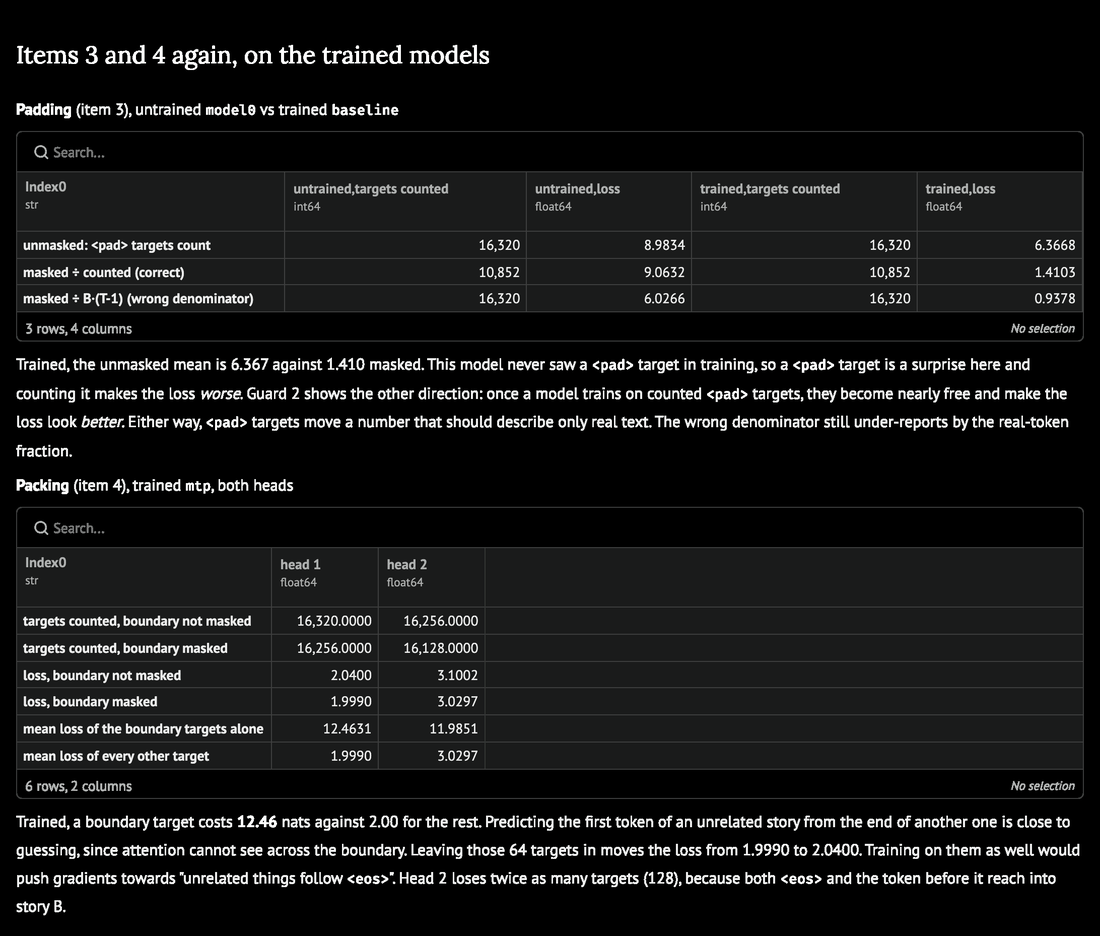

In [ ]:
pad_trained = padding_report(baseline)
pack_trained = packing_report(mtp)
_pc = pack_trained["head 1"]
mo.vstack([
    mo.md("## Items 3 and 4 again, on the trained models"),
    mo.md("**Padding** (item 3), untrained `model0` vs trained `baseline`"),
    pd.concat({"untrained": padding_frame(pad_untrained), "trained": padding_frame(pad_trained)}, axis=1).round(4),
    mo.md(f"""Trained, the unmasked mean is {pad_trained['loss'][0]:.3f} against {pad_trained['loss'][1]:.3f} masked. This model never saw a `<pad>` target in training, so a `<pad>` target is a surprise here and counting it makes the loss *worse*. Guard 2 shows the other direction: once a model trains on counted `<pad>` targets, they become nearly free and make the loss look *better*. Either way, `<pad>` targets move a number that should describe only real text. The wrong denominator still under-reports by the real-token fraction."""),
    mo.md("**Packing** (item 4), trained `mtp`, both heads"),
    pack_trained.round(4),
    mo.md(f"""Trained, a boundary target costs **{_pc['mean loss of the boundary targets alone']:.2f}** nats against {_pc['mean loss of every other target']:.2f} for the rest. Predicting the first token of an unrelated story from the end of another one is close to guessing, since attention cannot see across the boundary. Leaving those {B} targets in moves the loss from {_pc['loss, boundary masked']:.4f} to {_pc['loss, boundary not masked']:.4f}. Training on them as well would push gradients towards "unrelated things follow `<eos>`". Head 2 loses twice as many targets ({int(pack_trained.loc['targets counted, boundary not masked', 'head 2'] - pack_trained.loc['targets counted, boundary masked', 'head 2'])}), because both `<eos>` and the token before it reach into story B."""),
])

In [ ]:
_gap0 = val_table["L2 − L1"].iloc[1]
_gapN = val_table["L2 − L1"].iloc[-1]
_gmax_i = int(val_table["L2 − L1"].idxmax())
_drop1 = val_table["mtp L1"].iloc[1] - val_table["mtp L1"].iloc[-1]
_drop2 = val_table["mtp L2"].iloc[1] - val_table["mtp L2"].iloc[-1]
_tg = np.array(hist_mtp["train"]); _tg = _tg[:, 1] - _tg[:, 0]
_open = hist_mtp["step"][int(np.argmax(_tg >= 0.9 * _gapN))]
_pc = pack_trained["head 1"]
mo.md(f"""
# Write-up

## Part 1 · the seven numbers

| # | check | result |
|---|---|---|
| 1 | tensor shapes | `tokens [{B}, {CFG.T}]` → `hidden [{B}, {CFG.T}, {CFG.d}]` → `logits [{B}, {CFG.T}, {CFG.V}]` → loss inputs `[{N:,}, {CFG.V}]` vs `[{N:,}]` → scalar |
| 2 | the shift, as strings | inputs and targets line up one token apart in the item 2 table; the `<eos> → next story` target shows as `✗` |
| 3 | padding: contributing tokens | **{pad_untrained['targets counted'][0]:,} → {pad_untrained['targets counted'][1]:,}** once `<pad>` targets are masked ({(pad_x == PAD).float().mean().item():.1%} of the batch is padding) |
| 4 | packing: loss before → after the boundary mask (trained, head 1) | **{_pc['loss, boundary not masked']:.4f} → {_pc['loss, boundary masked']:.4f}**; a boundary target costs {_pc['mean loss of the boundary targets alone']:.2f} nats against {_pc['mean loss of every other target']:.2f} for the others (untrained: {pack_untrained.loc['loss, boundary not masked', 'head 1']:.4f} → {pack_untrained.loc['loss, boundary masked', 'head 1']:.4f}) |
| 5 | untrained perplexity | **{ppl0:,.0f}** against `V = {CFG.V:,}` (loss {l0:.4f}, `ln V = {math.log(CFG.V):.4f}`) |
| 6 | head parameters, tied vs untied | **{counts['tied']:,} vs {counts['untied']:,}**: tying saves `V·D = {head_params:,}` ({head_params / counts['untied']:.1%}) |
| 7 | peak memory of the loss, ordinary vs chunked | **{mem['ordinary MiB']:,.1f} MiB vs {mem['chunked MiB']:,.1f} MiB, {mem['ratio']:.1f}× less**, identical loss and gradients (at `B={B}`; {sweep_df['ratio'].iloc[-1]:.0f}× at `B={sweep_df['B'].iloc[-1]}`) |

Two failures from the warning were reproduced on purpose. The unshifted harness trains to **{guard_bug['train'][-1][0]:.3f}** nats in 300 steps by copying its input ({copy_rate:.1%} of argmaxes equal the input token). Counting `<pad>` in training reports a loss {pad_train_df.iloc[0, 1] - pad_train_df.iloc[0, 0]:.2f} nats better than masking, while the two models are within {abs(pad_train_df.iloc[2, 0] - pad_train_df.iloc[2, 1]):.3f} nats of each other on real tokens.

## Part 2 · the two losses

| final validation | head 1 (`t+1`) | head 2 (`t+2`) | sum |
|---|---:|---:|---:|
| `mtp` loss | **{ml1:.4f}** | **{ml2:.4f}** | **{ml1 + ml2:.4f}** |
| perplexity | {math.exp(ml1):.2f} | {math.exp(ml2):.2f} | |
| top-1 accuracy | {ma1:.1%} | {ma2:.1%} | |
| `baseline` (one head) | {bl1:.4f} | | |

**What happens to head 2's loss over training.** Both heads start at `ln V ≈ {math.log(CFG.V):.2f}` with no gap ({val_table['L2 − L1'].iloc[0]:.3f} nats at step 1). The gap opens fast: in the training log it reaches 90% of its final size by step **{_open}**. It peaks at **{val_table['L2 − L1'].iloc[_gmax_i]:.2f}** nats at step {val_table['step'].iloc[_gmax_i]}, then stays almost constant: {_gap0:.2f} at step {val_table['step'].iloc[1]}, {_gapN:.2f} at the end. From step {val_table['step'].iloc[1]} on, head 1 falls by {_drop1:.2f} nats and head 2 by {_drop2:.2f}, nearly the same amount. So head 2 is not learning more slowly. It runs a fixed ~1 nat behind and never catches up. Because L1 keeps falling while the gap does not, the **ratio** `L2 / L1` rises from {val_table['L2 / L1'].iloc[1]:.2f} to {val_table['L2 / L1'].iloc[-1]:.2f}. In relative terms head 2 looks worse and worse, even though in absolute terms it keeps pace.

**Why.** Head 2 must predict token `t+2` without seeing token `t+1`, so it has to average over every `t+1` that could come next. Its best possible loss is the entropy `H(x_{{t+2}} | x_{{≤t}})`, and that is at least `H(x_{{t+1}} | x_{{≤t}})`, because the unseen token adds uncertainty. For the first few dozen steps both heads learn only token frequencies, and the frequency of token `t+2` is the same as that of `t+1`, so the losses match. As soon as the model uses context, head 1 profits from the sharpest dependency in text, the one on the token right before it (finishing a word or a fixed phrase: `" Once upon a" → " time"`). Head 2 gets only what survives one unseen token. That is the ~1 nat that opens early. After that, the trunk's improvements (who the story is about, what happened, grammar) help both heads about equally, which is why the gap stays flat instead of shrinking. The gap measures the extra entropy of looking two tokens ahead, not under-training.

**Effect on head 1.** With the extra head, head 1 ends at {ml1:.4f} against {bl1:.4f} for the baseline ({ml1 - bl1:+.4f} nats). The trunk is the same size and now has to serve two objectives, so at {counts['block'] * CFG.L / 1e6:.1f}M trunk parameters and {STEPS:,} steps the extra supervision does {"not pay for itself in next-token loss" if ml1 > bl1 else "help next-token loss slightly"}. The MTP literature reports its training gains at much larger scale.

**As a draft head.** Used greedily for self-speculation, head 2's draft matches head 1's verified token at `t+1` **{drafts['acceptance: head-2 draft == head-1 greedy at t+1']:.1%}** of the time. That acceptance rate, not the loss, decides whether MTP pays at inference.
""")

<span class="markdown prose dark:prose-invert contents"><h1 id="write-up">Write-up</h1>
<h2 id="part-1-the-seven-numbers">Part 1 · the seven numbers</h2>
<table>
<thead>
<tr>
<th>#</th>
<th>check</th>
<th>result</th>
</tr>
</thead>
<tbody>
<tr>
<td>1</td>
<td>tensor shapes</td>
<td><code>tokens [64, 256]</code> → <code>hidden [64, 256, 256]</code> → <code>logits [64, 256, 8192]</code> → loss inputs <code>[16,320, 8192]</code> vs <code>[16,320]</code> → scalar</td>
</tr>
<tr>
<td>2</td>
<td>the shift, as strings</td>
<td>inputs and targets line up one token apart in the item 2 table; the <code>&lt;eos&gt; → next story</code> target shows as <code>✗</code></td>
</tr>
<tr>
<td>3</td>
<td>padding: contributing tokens</td>
<td><strong>16,320 → 10,852</strong> once <code>&lt;pad&gt;</code> targets are masked (33.4% of the batch is padding)</td>
</tr>
<tr>
<td>4</td>
<td>packing: loss before → after the boundary mask (trained, head 1)</td>
<td><strong>2.0400 → 1.9990</strong>; a boundary target costs 12.46 nats against 2.00 for the others (untrained: 9.0632 → 9.0624)</td>
</tr>
<tr>
<td>5</td>
<td>untrained perplexity</td>
<td><strong>8,693</strong> against <code>V = 8,192</code> (loss 9.0702, <code>ln V = 9.0109</code>)</td>
</tr>
<tr>
<td>6</td>
<td>head parameters, tied vs untied</td>
<td><strong>8,589,568 vs 10,686,720</strong>: tying saves <code>V·D = 2,097,152</code> (19.6%)</td>
</tr>
<tr>
<td>7</td>
<td>peak memory of the loss, ordinary vs chunked</td>
<td><strong>1,530.0 MiB vs 119.9 MiB, 12.8× less</strong>, identical loss and gradients (at <code>B=64</code>; 68× at <code>B=1024</code>)</td>
</tr>
</tbody>
</table>
<span class="paragraph">Two failures from the warning were reproduced on purpose. The unshifted harness trains to <strong>0.009</strong> nats in 300 steps by copying its input (99.9% of argmaxes equal the input token). Counting <code>&lt;pad&gt;</code> in training reports a loss 0.56 nats better than masking, while the two models are within 0.017 nats of each other on real tokens.</span>
<h2 id="part-2-the-two-losses">Part 2 · the two losses</h2>
<table>
<thead>
<tr>
<th>final validation</th>
<th style="text-align: right;">head 1 (<code>t+1</code>)</th>
<th style="text-align: right;">head 2 (<code>t+2</code>)</th>
<th style="text-align: right;">sum</th>
</tr>
</thead>
<tbody>
<tr>
<td><code>mtp</code> loss</td>
<td style="text-align: right;"><strong>1.8955</strong></td>
<td style="text-align: right;"><strong>2.8931</strong></td>
<td style="text-align: right;"><strong>4.7886</strong></td>
</tr>
<tr>
<td>perplexity</td>
<td style="text-align: right;">6.66</td>
<td style="text-align: right;">18.05</td>
<td style="text-align: right;"></td>
</tr>
<tr>
<td>top-1 accuracy</td>
<td style="text-align: right;">54.8%</td>
<td style="text-align: right;">38.3%</td>
<td style="text-align: right;"></td>
</tr>
<tr>
<td><code>baseline</code> (one head)</td>
<td style="text-align: right;">1.8565</td>
<td style="text-align: right;"></td>
<td style="text-align: right;"></td>
</tr>
</tbody>
</table>
<span class="paragraph"><strong>What happens to head 2's loss over training.</strong> Both heads start at <code>ln V ≈ 9.01</code> with no gap (0.009 nats at step 1). The gap opens fast: in the training log it reaches 90% of its final size by step <strong>100</strong>. It peaks at <strong>1.04</strong> nats at step 750, then stays almost constant: 1.00 at step 250, 1.00 at the end. From step 250 on, head 1 falls by 1.20 nats and head 2 by 1.20, nearly the same amount. So head 2 is not learning more slowly. It runs a fixed ~1 nat behind and never catches up. Because L1 keeps falling while the gap does not, the <strong>ratio</strong> <code>L2 / L1</code> rises from 1.32 to 1.53. In relative terms head 2 looks worse and worse, even though in absolute terms it keeps pace.</span>
<span class="paragraph"><strong>Why.</strong> Head 2 must predict token <code>t+2</code> without seeing token <code>t+1</code>, so it has to average over every <code>t+1</code> that could come next. Its best possible loss is the entropy <code>H(x_{t+2} | x_{≤t})</code>, and that is at least <code>H(x_{t+1} | x_{≤t})</code>, because the unseen token adds uncertainty. For the first few dozen steps both heads learn only token frequencies, and the frequency of token <code>t+2</code> is the same as that of <code>t+1</code>, so the losses match. As soon as the model uses context, head 1 profits from the sharpest dependency in text, the one on the token right before it (finishing a word or a fixed phrase: <code>" Once upon a" → " time"</code>). Head 2 gets only what survives one unseen token. That is the ~1 nat that opens early. After that, the trunk's improvements (who the story is about, what happened, grammar) help both heads about equally, which is why the gap stays flat instead of shrinking. The gap measures the extra entropy of looking two tokens ahead, not under-training.</span>
<span class="paragraph"><strong>Effect on head 1.</strong> With the extra head, head 1 ends at 1.8955 against 1.8565 for the baseline (+0.0390 nats). The trunk is the same size and now has to serve two objectives, so at 6.4M trunk parameters and 5,000 steps the extra supervision does not pay for itself in next-token loss. The MTP literature reports its training gains at much larger scale.</span>
<span class="paragraph"><strong>As a draft head.</strong> Used greedily for self-speculation, head 2's draft matches head 1's verified token at <code>t+1</code> <strong>54.1%</strong> of the time. That acceptance rate, not the loss, decides whether MTP pays at inference.</span></span>